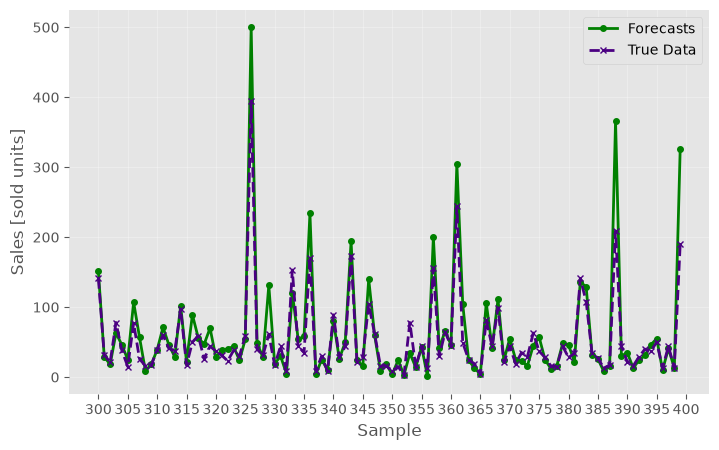

<Figure size 640x480 with 0 Axes>

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

experiment = "price"

plt.style.use('ggplot')

final_results = pd.read_csv(f"predictions/predictions_no_calendar_year_{experiment}_xgb.csv", header=None)

true_data = pd.read_csv(f"testsets/test_no_calendar_year_{experiment}_xgb.csv")

pred = final_results.dropna().iloc[300:400].values
true = true_data['GesamtmengeVj'].dropna().iloc[300:400].values

x = list(range(300, 400))

ax = plt.axes((0.1, 0.1, 1.0, 0.8))
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['top'].set_visible(False)

ax.plot(x, true, marker='o', markersize=4, markerfacecolor='green',
        markeredgecolor='green', markeredgewidth=1, color='green',
        linestyle='-', linewidth=2)
ax.plot(x, pred, marker='x', markersize=4, markerfacecolor='indigo',
        markeredgecolor='indigo', markeredgewidth=1, color='indigo',
        linestyle='--', linewidth=2)

ax.grid(True, which='major', axis='both', alpha=0.3)

plt.xlabel("Sample")
plt.ylabel("Sales [sold units]")

ax.xaxis.set_major_locator(plt.MaxNLocator(25))

ax.legend(['Forecasts', "True Data"], frameon=True)

fig1 = plt.gcf()
plt.show()
plt.draw()

fig1.savefig(f'Plots/Plot_predictions_{experiment}.pdf', format='pdf', bbox_inches='tight')

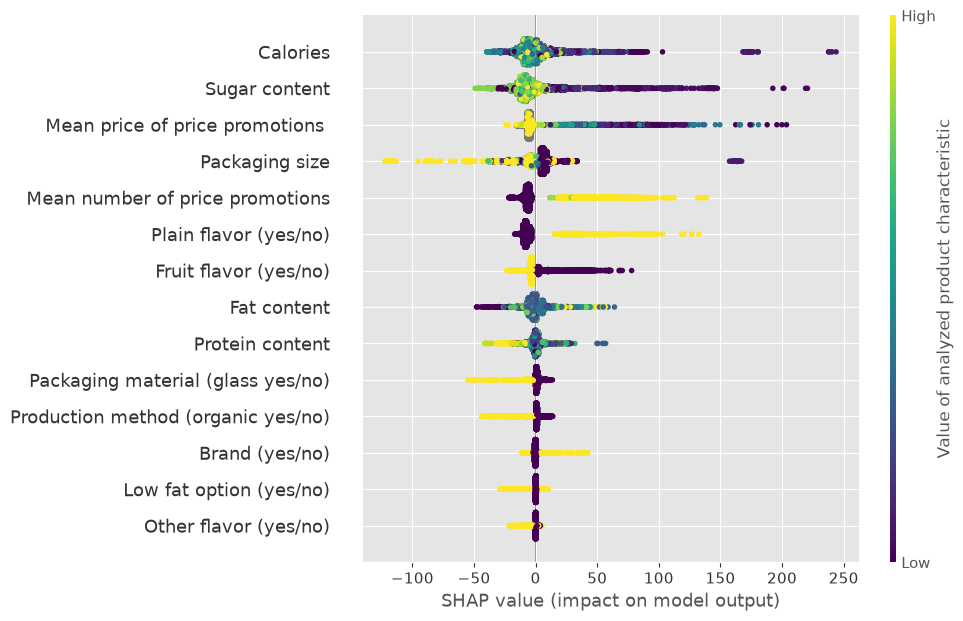

<Figure size 640x480 with 0 Axes>

In [12]:
import pickle
import shap
import matplotlib.pyplot as plt
filename_shap = 'shapvalues_no_calendar_year_price.sav'
shap_values = pickle.load(open("shapvalues/" + filename_shap, 'rb'))
shap_values.feature_names = ["Brand (yes/no)", "Plain flavor (yes/no)", "Fruit flavor (yes/no)", 
                             "Other flavor (yes/no)", "Packaging size", "Fat content", "Low fat option (yes/no)", "Calories",
                             "Protein content", "Sugar content", "Production method (organic yes/no)",
                             "Packaging material (glass yes/no)", "Mean price of price promotions ",
                             "Mean number of price promotions"]
# ["Brand (yes/no)", "Plain flavor (yes/no)", "Fruit flavor (yes/no)", "Other flavor (yes/no)", "Packaging size", "Fat content", "Low fat option (yes/no)", "Calories", "Protein content", "Sugar content", "Production method (organic yes/no)", "Packaging material (glass yes/no)", "Price", "Mean price of price promotions ", "Mean number of price promotions"]
shap.plots.beeswarm(shap_values, max_display=38, color="viridis", show=False, order=shap_values.abs.max(0), color_bar_label="Value of analyzed product characteristic")
fig1 = plt.gcf()
plt.show()
plt.draw()
fig1.savefig(f'Plots/beeplot_{filename_shap}.pdf', format='pdf', bbox_inches='tight')